In [1]:
# Imports

from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, TensorDataset, DataLoader
from scipy.stats import binned_statistic

import sys
sys.path.insert(0, '../')

import pandas as pd
import torch.nn as nn
from time import perf_counter
from scipy.stats import circmean

from src.network import Network
from src.plot_utils import plot_con
from src.decode import *
from src.lr_utils import masked_normalize, clamp_tensor, normalize_tensor
from src.utils import clear_cache

import pickle as pkl
import os

import seaborn as sns
import matplotlib.pyplot as plt

def pkl_save(obj, name, path="."):
    os.makedirs(path, exist_ok=True)
    destination = path + "/" + name + ".pkl"
    print("saving to", destination)
    pkl.dump(obj, open(destination, "wb"))


def pkl_load(name, path="."):
    source = path + "/" + name + '.pkl'
    # print('loading from', source)
    return pkl.load(open( source, "rb"))



In [2]:


# Notebook Settings

%load_ext autoreload
%autoreload 2
%reload_ext autoreload

# %run ../notebooks/setup.py
# %matplotlib inline
# %config InlineBackend.figure_format = 'png'

REPO_ROOT = "/home/leon/models/NeuroFlame"
pal = sns.color_palette("tab10")


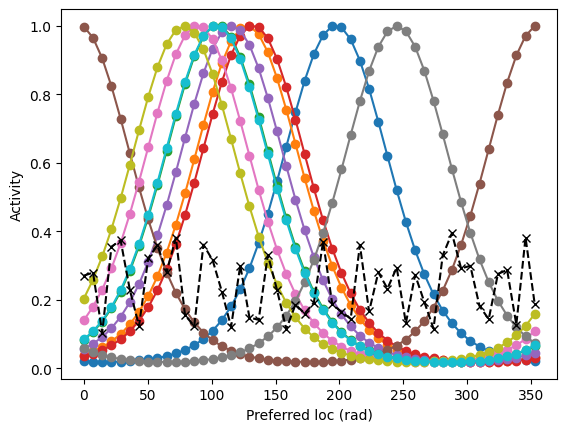

torch.Size([10, 50, 50])
torch.Size([10, 50, 50])
torch.Size([10, 50, 50])
torch.Size([10, 50, 50])


In [3]:
# Hebb

from src.hebbian import Hebbian

import torch
import numpy as np
import matplotlib.pyplot as plt

N_BATCH = 10
N_NEURONS = 50

# Make preferred positions evenly spaced on [0, 2π)
theta_neurons = 2 * np.pi * torch.arange(N_NEURONS) / N_NEURONS

# Random bump centers for each batch
bump_centers = 2 * np.pi * torch.rand(N_BATCH, 1)
WIDTH = 2.0

# Compute activity rates (N_BATCH, N_NEURONS)
rates = torch.exp(WIDTH * torch.cos(theta_neurons - bump_centers))
rates = rates / rates.max(dim=1, keepdim=True)[0]

# Baseline (random example)
avg_rates = 0.1 + 0.3 * torch.rand(N_NEURONS)

x = theta_neurons.numpy() * 180 / np.pi

bump_centers *= 180 / np.pi

plt.figure()

# Plot bumps for each batch
for n in range(N_BATCH):
    plt.plot(x, rates[n].numpy(), label=f'batch {n+1}: {bump_centers[n,0]:.2f}', marker='o')

plt.plot(x, avg_rates.numpy(), color='k', linestyle='--', marker='x')
plt.xlabel('Preferred loc (rad)')
plt.ylabel('Activity')
# plt.legend(fontsize=12, frameon=0)
plt.show()

ETA = 1
DT = 0.1

hebb = Hebbian(ETA, DT, HEBB_TYPE="")
wij = hebb(rates, rates)
print(wij.shape)

hebb_cov = Hebbian(ETA, DT, HEBB_TYPE="cov")
wij_cov = hebb_cov(rates, rates, avg_rates, avg_rates)
print(wij_cov.shape)

bcm = Hebbian(ETA, DT, HEBB_TYPE="bcm")
wij_bcm = bcm(rates, rates, avg_rates, avg_rates)
print(wij_bcm.shape)

hebb_corr = Hebbian(ETA, DT, HEBB_TYPE="corr")
wij_corr = hebb_corr(rates, rates, avg_rates, avg_rates)
print(wij_corr.shape)

wij_list = [wij, wij_cov, wij_bcm, wij_corr]



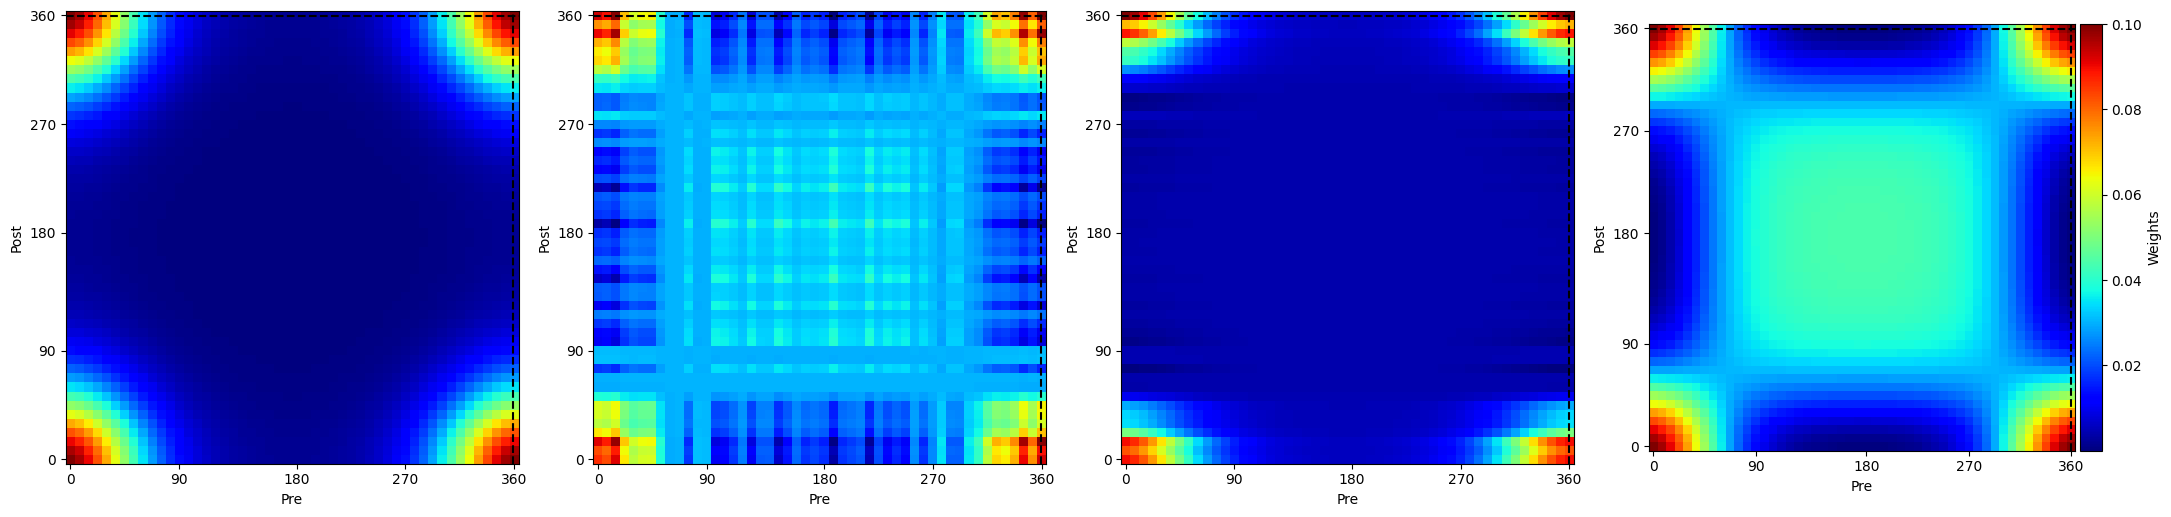

In [31]:

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
width = 7
height = 5
fig, ax = plt.subplots(1, 4, figsize=(4 * 0.75 * width, 0.75 * width), constrained_layout=True)
idx = np.random.randint(N_BATCH)
im_list = []

n = wij_list[0][idx].shape[0]
extent = [0, 360, 0, 360]
centers = np.linspace(0 + 360/(2*n), 360 - 360/(2*n), n)

# Your desired tick positions
tick_labels = np.linspace(0, 360, 5)
# For each label, find the closest center
tick_locs = [centers[np.argmin(np.abs(centers - t))] for t in tick_labels]

for i in range(4):
    im = ax[i].imshow(
        wij_list[i][idx],
        aspect='equal',
        extent=extent,
        cmap='jet',
        origin='lower'
    )
    im_list.append(im)
    ax[i].axvline(bump_centers[idx, 0], ls='--', color='k')
    ax[i].axhline(bump_centers[idx, 0], ls='--', color='k')
    # Set pixel-centered ticks closest to your desired values
    ax[i].set_xticks(tick_locs)
    ax[i].set_xticklabels([f"{int(t)}" for t in tick_labels])
    ax[i].set_yticks(tick_locs)
    ax[i].set_yticklabels([f"{int(t)}" for t in tick_labels])
    ax[i].set_xlabel('Pre')
    ax[i].set_ylabel('Post')

divider = make_axes_locatable(ax[-1])
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = fig.colorbar(im_list[0], cax=cax)
cbar.set_label('Weights')

plt.show()


In [5]:


# Model

kwargs = {
    'GAIN': 1.0,
    'DURATION': 9.0,
    'T_STEADY': 5.0,

    'T_STIM_ON': [1.0, 8.0],
    'T_STIM_OFF': [2.0, 9.0],

    'I0': [1.0, -10.0],
    'PHI0': [180.0, 180],
    'SIGMA0': [1.0, 0.0],
    'M0': 1.0,
    'VAR_FF': [0.2, 0.2],

    'RANDOM_DELAY': 0,
    'TAU': [0.2, 0.1],

    'SYN_DYN': 0,

    'IF_NMDA': 1,
    'R_NMDA': 1.0,
    'TAU_NMDA': [1.0, 1.0],

    'Jab': [1.0, -1.4, 1.0, -1],

    'IF_STP': 0,

    'IF_ADAPT': 0,
    'A_ADAPT': 0.5, # 4 or 0.5 0.15 or 1.5
    'TAU_ADAPT': 10.0,

    'IF_HEBB': 1,
    'IS_HEBB': [1, 0, 0, 0],
    'TAU_HEBB': 1,
    'T_HEBB': 5,
    'ETA': 2.5,
    'HEBB_TYPE': 'corr'
}


In [6]:

REPO_ROOT = "/home/leon/models/NeuroFlame"
conf_name = "train_odr_EI.yml"
DEVICE = 'cuda'
seed = np.random.randint(0, 1e6)

seed = 1
print('seed', seed)



seed 1


In [7]:


N_BATCH = 10
model = Network(conf_name, REPO_ROOT, VERBOSE=0, DEVICE=DEVICE, SEED=seed, N_BATCH=N_BATCH, **kwargs)

model = model.to(DEVICE)
model.eval();

model.N_BATCH = N_BATCH

model.I0 = kwargs['I0']

model.TASK: 'odr'
model.PHI0 = torch.randint(low=0, high=360, size=(N_BATCH, len(model.I0), 1), device=DEVICE, dtype=torch.float)

with torch.no_grad():
    ff_input = model.init_ff_input()
    rates = model.forward(ff_input=ff_input, IF_INIT=1)
    clear_cache()
print(ff_input.shape, rates.shape)


750
250
torch.Size([10, 955, 1000]) torch.Size([10, 91, 750])


In [8]:


DURATION = kwargs['DURATION']
N_NEURONS = rates.shape[-1]
N_SESSION = rates.shape[0]


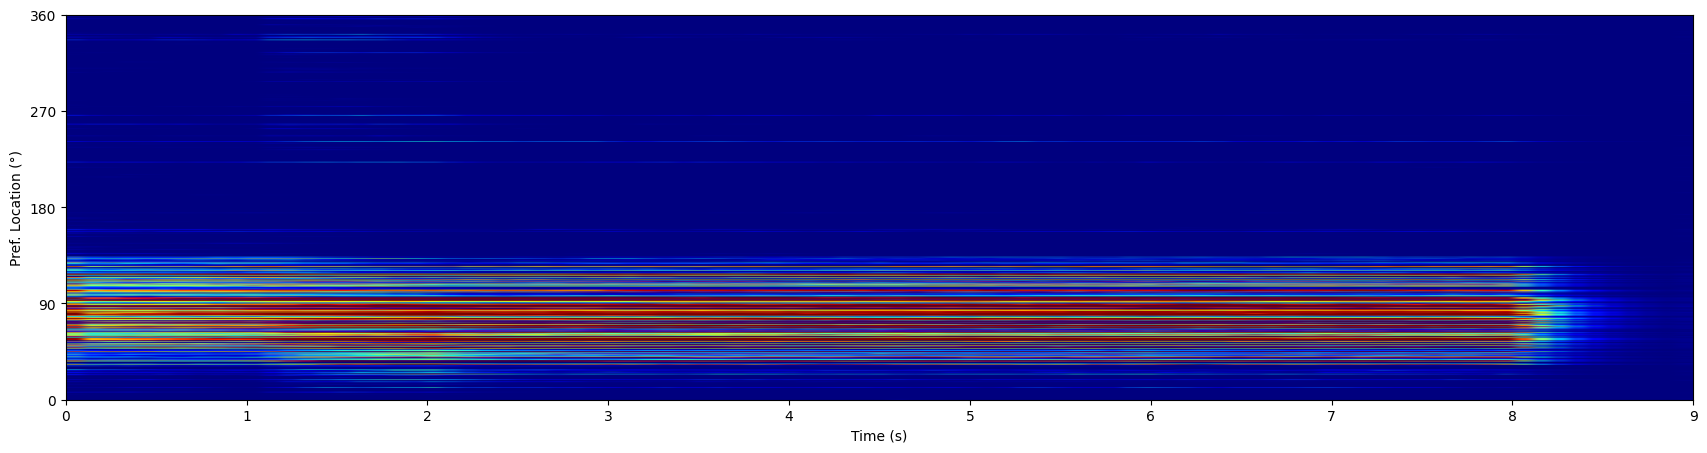

In [9]:

fig, ax = plt.subplots(1, 1, figsize=[3*width, height])

idx = np.random.randint(0, N_SESSION)

vmin, vmax = np.nanpercentile(rates[idx, :, model.slices[0]].cpu().reshape(-1), [5, 95])

plt.imshow(rates[idx, :, model.slices[0]].cpu().T, aspect='auto', cmap='jet', vmin=vmin, vmax=vmax, origin='lower', extent=[0, DURATION, 0, N_NEURONS])
plt.ylabel('Pref. Location (°)')
plt.yticks(np.linspace(0, N_NEURONS, 5), np.linspace(0, 360, 5).astype(int))
plt.xlabel('Time (s)')

plt.show()


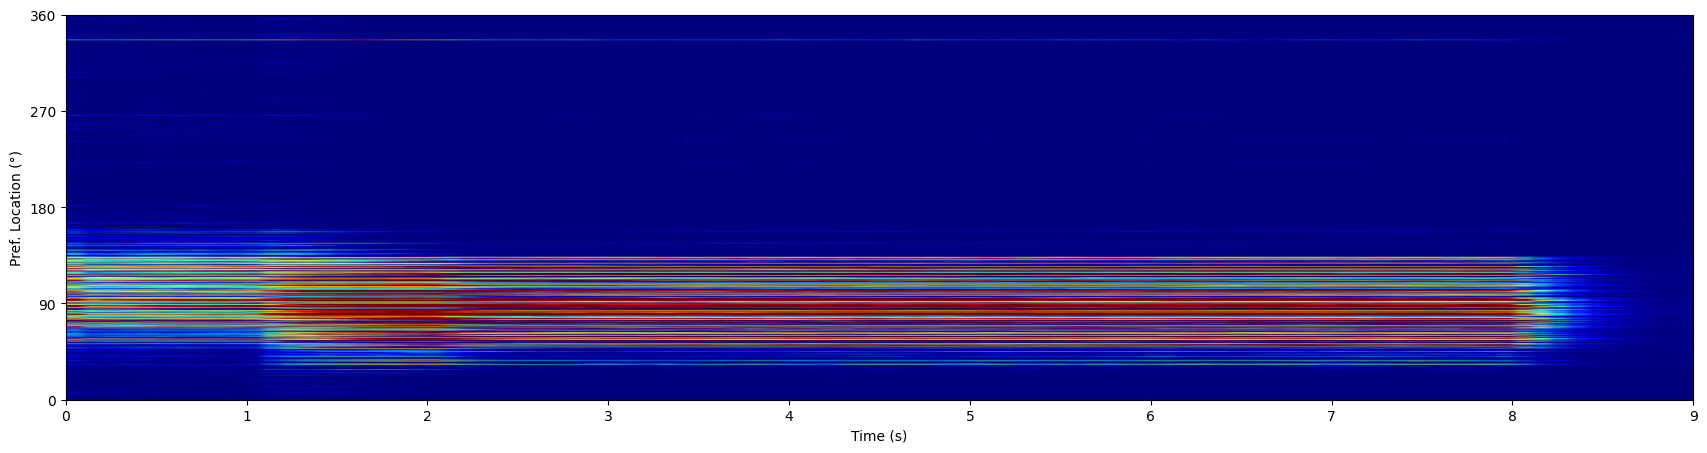

In [10]:

fig, ax = plt.subplots(1, 1, figsize=[3*width, height])

idx = np.random.randint(0, N_SESSION)

vmin, vmax = np.nanpercentile(rates[idx, :, model.slices[0]].cpu().reshape(-1), [5, 95])

plt.imshow(rates[idx, :, model.slices[0]].cpu().T, aspect='auto', cmap='jet', vmin=vmin, vmax=vmax, origin='lower', extent=[0, DURATION, 0, N_NEURONS])
plt.ylabel('Pref. Location (°)')
plt.yticks(np.linspace(0, N_NEURONS, 5), np.linspace(0, 360, 5).astype(int))
plt.xlabel('Time (s)')

plt.show()


In [11]:

m0_list, m1_list, phi_list = decode_bump_torch(rates[..., model.slices[0]], axis=-1, RET_TENSOR=0)
print(phi_list.shape)


(10, 91)


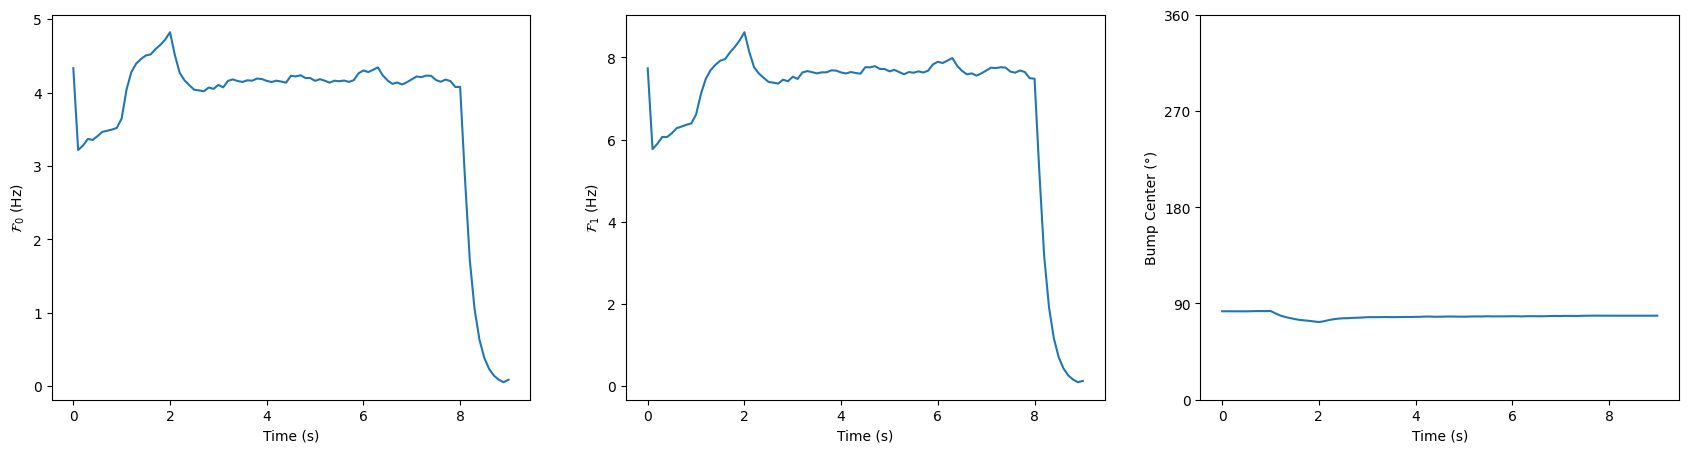

In [12]:

fig, ax = plt.subplots(1, 3, figsize=[3*width, height])

idx = np.random.randint(0, model.N_BATCH)

m0 = np.hstack(m0_list[idx]).T
m1 = np.hstack(m1_list[idx]).T
phi = np.hstack(phi_list[idx]).T

xtime = np.linspace(0, DURATION, phi.shape[-1])

ax[0].plot(xtime, m0)
ax[0].set_ylabel('$\mathcal{F}_0$ (Hz)')
ax[0].set_xlabel('Time (s)')

ax[1].plot(xtime, m1)
ax[1].set_ylabel('$\mathcal{F}_1$ (Hz)')
ax[1].set_xlabel('Time (s)')

ax[2].plot(xtime, phi * 180 / np.pi)
ax[2].set_yticks(np.linspace(0, 360, 5).astype(int), np.linspace(0, 360, 5).astype(int))
ax[2].set_ylabel('Bump Center (°)')
ax[2].set_xlabel('Time (s)')

plt.show()
